# Finance-IDC: End-to-End Data, Sentiment, Modelling and Forecasting Walkthrough

**Project:** NIFTY 50 next-session forecasting using market data and financial-news sentiment  
**Purpose:** Explain the implemented pipeline, inspect the actual local data, understand every transformation, and interpret the forecast without overstating what the model can establish.

> **How to use this notebook**
>
> 1. Place this notebook in the root of the `finance-IDC-Project` repository (beside `run_pipeline.py`).
> 2. Activate the project's `finance-IDC` Conda environment and select that Python kernel.
> 3. Run the cells from top to bottom. The inspection cells read your existing files; they do not recollect data or modify the database.
> 4. Paths are relative to the project root. If you launch Jupyter from another directory, change `PROJECT_ROOT` below.

This notebook documents the implemented code and the latest successful pipeline run. It is not a claim that the forecasting model is profitable or statistically validated.

## 1. Project objective and prediction tasks

The system combines two information streams:

- **Market data:** daily NIFTY 50 OHLCV observations and derived returns/technical summaries.
- **News data:** financial-news headlines, publication timestamps, source metadata, and FinBERT sentiment outputs.

The pipeline produces three next-session estimates:

1. **Return regression:** estimate the next trading session's NIFTY 50 percentage return.
2. **Direction classification:** estimate the probability that the next session's return is positive (`P(UP)`).
3. **Volatility classification:** estimate the probability that the absolute next-session return exceeds a threshold derived from past market returns.

The target is the *next available trading session*, not necessarily the next calendar day. Weekends and exchange holidays are skipped because the target is constructed from the next row in the trading-session price series.

### Target definition

For trading session \(t\), the target is:

\[
y_t = 100\left(\frac{C_{t+1}}{C_t}-1\right)
\]

where \(C_t\) is the NIFTY 50 close on session \(t\), and \(C_{t+1}\) is the close on the next available trading session.

The direction label is:

\[
d_t = \mathbb{1}(y_t > 0)
\]

A zero return is therefore not classified as UP.

## 2. End-to-end architecture

The actual `run_pipeline.py` stage order is:

```text
Google News RSS + historical news CSVs       Yahoo Finance (^NSEI)
                  |                                  |
          recent_news_2026.csv               nifty50_processed.csv
                  |                                  |
                  +---------------+------------------+
                                  |
                         import_collected_data.py
                                  |
                          SQLite: data/market.db
                                  |
                         align_news_market.py
                                  |
                 news_market_alignment.csv
                    news_market_daily.csv
                                  |
                       analyze_news_sentiment.py
                                  |
               news_sentiment_scored.csv
                news_sentiment_daily.csv
                                  |
                       build_training_dataset.py
                                  |
             monthly sampled training article set
                    model_dataset.csv
                                  |
                       generate_forecast.py
                                  |
       adaptive walk-forward selection + final models
                                  |
                     latest_forecast.csv
                                  |
                    record_forecast_outcome.py
                                  |
                  forecast_outcome_history.csv
```

The full scored archive is retained. Historical model training uses a sampled article archive; the live seven-day feature vector is rebuilt from the full scored archive.

**Run commands from the repository root:**

```powershell
conda activate finance-IDC
python run_pipeline.py
```

Use existing local data without re-running collection/import:

```powershell
python run_pipeline.py --skip-refresh
```

Run only selected downstream stages:

```powershell
python run_pipeline.py --only align,sentiment,dataset,forecast,outcomes
```

## 3. Imports and project paths

The main implementation uses:

- `pandas` and `numpy` for tabular processing and numerical transformations.
- `sqlite3` for persistent local storage.
- `requests` and `feedparser` for Google News RSS collection.
- `yfinance` for daily NIFTY 50 data.
- `transformers` and `torch` to run FinBERT.
- `scikit-learn` for preprocessing, regression, classification, and evaluation.
- `matplotlib` for exploratory plots.

The following cells inspect the files produced by the pipeline. They do not call the external services.

In [1]:
from pathlib import Path
import sqlite3
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "run_pipeline.py").exists():
    raise FileNotFoundError(
        "This notebook must be run from the finance-IDC-Project root "
        "or PROJECT_ROOT must be set to that directory."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DB_PATH = PROJECT_ROOT / "data" / "market.db"

print("Project root:", PROJECT_ROOT)
print("Database exists:", DB_PATH.exists())
print("Raw directory exists:", RAW_DIR.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())

Project root: C:\Users\surya\Documents\finance-IDC-Project
Database exists: True
Raw directory exists: True
Processed directory exists: True


## 4. Data collection

### 4.1 Financial news

`src/collect_recent_news.py` collects recent articles from **Google News RSS**. The collector searches a predefined set of terms, including:

- India stock market
- Sensex
- NIFTY 50
- Indian economy
- RBI India
- Indian stock market earnings
- India inflation and interest rates
- Reliance Industries earnings
- Tata Consultancy Services earnings
- NSE/BSE market news

For each RSS entry it attempts to retain:

| Field | Meaning |
|---|---|
| `title` | Headline text; this is what FinBERT later analyses |
| `published_at` | Publication timestamp, normalized to UTC |
| `publication_date` | Date derived from publication timestamp |
| `source` | Publisher/source name supplied by the RSS entry |
| `url` | Article URL; primary deduplication key |
| `matched_terms` | Search term that retrieved the entry |
| `requested_month` | Publication month |
| `collected_at` | Time the pipeline collected the entry |

The collector uses a rolling seven-day overlap when it runs again. This overlap helps discover late-indexed RSS entries. It retains previously saved articles and deduplicates by URL. The historical 2021–2025 news corpus is loaded from a separate local CSV; its upstream collection provenance is not established by the current collector code, so do not describe it as having been collected by the current RSS run.

**Important limitation:** RSS search is not a complete census of all financial news. Search-term choice, publisher indexing, RSS availability, and collection timing affect which articles enter the archive.

In [2]:
news_recent_path = RAW_DIR / "recent_news_2026.csv"
news_historical_candidates = [
    RAW_DIR / "historical_news_merged_2021_2025.csv",
    RAW_DIR / "historical_news_2021_2025.csv",
]

print("Recent news file exists:", news_recent_path.exists())
print("Historical news candidates:")
for p in news_historical_candidates:
    print(" ", p.name, "->", p.exists())

if news_recent_path.exists():
    recent_news = pd.read_csv(news_recent_path)
    print("\nRecent-news shape:", recent_news.shape)
    display(recent_news.head())
    display(recent_news.dtypes.to_frame("dtype"))

Recent news file exists: True
Historical news candidates:
  historical_news_merged_2021_2025.csv -> True
  historical_news_2021_2025.csv -> True

Recent-news shape: (6859, 8)


,title,published_at,publication_date,source,url,matched_terms,requested_month,collected_at
0,Indian stock market rings in New Year with gai...,2026-01-01 04:32:00+00:00,2026-01-01,DD News,https://news.google.com/rss/articles/CBMilgFBV...,India stock market,2026-01,2026-10-28T03:19:48.579302+00:00
1,"Stock market today: Nifty50 opens above 26,150...",2026-01-01 08:00:00+00:00,2026-01-01,The Times of India,https://news.google.com/rss/articles/CBMinAJBV...,India stock market,2026-01,2026-10-28T03:19:48.586538+00:00
2,"Stock market outlook 2026: Why did Sensex, Nif...",2026-01-01 08:00:00+00:00,2026-01-01,The Times of India,https://news.google.com/rss/articles/CBMisAJBV...,India stock market,2026-01,2026-10-28T03:19:48.620199+00:00
3,India's Nifty 50 hits record high as investors...,2026-01-01 08:00:00+00:00,2026-01-01,Reuters,https://news.google.com/rss/articles/CBMixgFBV...,India stock market; Indian stock market earnin...,2026-01,2026-10-28T03:17:33.184776+00:00
4,Press Releases - Reserve Bank of India,2026-01-01 08:00:00+00:00,2026-01-01,Reserve Bank of India,https://news.google.com/rss/articles/CBMic0FVX...,RBI India,2026-01,2026-10-28T03:20:02.879151+00:00


,dtype
title,str
published_at,str
publication_date,str
source,str
url,str
matched_terms,str
requested_month,str
collected_at,str


### 4.2 NIFTY 50 market prices

`src/collect_prices.py` downloads the daily `^NSEI` ticker from Yahoo Finance using `yfinance`.

The first run requests history from **1 January 2021**. Subsequent runs refresh an overlap of seven calendar days from the latest saved date, merge it with the existing history, and keep the newest row for duplicate dates.

The raw price fields are typically:

- `Date`
- `Open`
- `High`
- `Low`
- `Close`
- `Adj Close` (when returned)
- `Volume`

The script recalculates derived variables over the retained history:

\[
r_t = \frac{C_t-C_{t-1}}{C_{t-1}}, \qquad
r_t^{(\%)} = 100r_t
\]

It also calculates daily range (`High - Low`), intraday percentage change, and calendar fields. The current date is excluded so an unfinished session is not treated as a completed daily observation.

The price collector can fail due to Yahoo Finance/network availability. A successful downstream run with `--skip-refresh` only proves that the existing local price file can be processed; it does not prove that the latest prices were refreshed.

In [3]:
price_path = PROCESSED_DIR / "nifty50_processed.csv"
if price_path.exists():
    prices = pd.read_csv(price_path, parse_dates=["Date"])
    print("Price data shape:", prices.shape)
    print("Date range:", prices["Date"].min(), "to", prices["Date"].max())
    display(prices.head())
    display(prices.tail())
    display(prices.isna().sum().to_frame("missing values"))
else:
    print("Missing:", price_path)

Price data shape: (1439, 14)
Date range: 2021-01-01 00:00:00 to 2026-10-29 00:00:00


,Date,Adj_Close,Close,High,Low,Open,Volume,Daily_Return,Daily_Return_Pct,Daily_Range,Intraday_Change_Pct,Year,Month,Year_Month
0,2021-01-01,14018.500000,14018.500000,14049.849609,13991.349609,13996.099609,358100,NaN,NaN,58.500000,0.160047,2021,1,2021-01
1,2021-01-04,14132.900391,14132.900391,14147.950195,13953.750000,14104.349609,495000,0.008161,0.816067,194.200195,0.202425,2021,1,2021-01
2,2021-01-05,14199.500000,14199.500000,14215.599609,14048.150391,14075.150391,492500,0.004712,0.471238,167.449219,0.883469,2021,1,2021-01
3,2021-01-06,14146.250000,14146.250000,14244.150391,14039.900391,14240.950195,632300,-0.003750,-0.375013,204.250000,-0.664985,2021,1,2021-01
4,2021-01-07,14137.349609,14137.349609,14256.250000,14123.099609,14253.750000,559200,-0.000629,-0.062917,133.150391,-0.816630,2021,1,2021-01


,Date,Adj_Close,Close,High,Low,Open,Volume,Daily_Return,Daily_Return_Pct,Daily_Range,Intraday_Change_Pct,Year,Month,Year_Month
1434,2026-10-23,22600.000000,22600.000000,22787.250000,22372.000000,22742.199219,364200,-0.003863,-0.386335,415.250000,-0.625266,2026,10,2026-10
1435,2026-10-26,22753.199219,22753.199219,22753.199219,22387.349609,22524.400391,310200,0.006779,0.677873,365.849609,1.015782,2026,10,2026-10
1436,2026-10-27,22749.750000,22749.750000,22829.750000,22636.849609,22708.800781,400900,-0.000152,-0.015159,192.900391,0.180323,2026,10,2026-10
1437,2026-10-28,22698.849609,22698.849609,22778.050781,22497.699219,22678.000000,295000,-0.002237,-0.223740,280.351562,0.091938,2026,10,2026-10
1438,2026-10-29,22842.150391,22842.150391,22874.150391,22656.750000,22690.650391,0,0.006313,0.631313,217.400391,0.667676,2026,10,2026-10


,missing values
Date,0
Adj_Close,0
Close,0
High,0
Low,0
Open,0
Volume,0
Daily_Return,1
Daily_Return_Pct,1
Daily_Range,0


## 5. Import and database structure

`src/import_collected_data.py` imports news and price rows into `data/market.db`.

### Main SQLite tables

**`news`**

- `id`: local primary key
- `title`
- `published_at`
- `source`
- `url`: unique key
- `collected_at`
- `matched_terms`
- `requested_month`

**`market_prices`**

- `id`: local primary key
- `ticker`
- `date`
- `open`, `high`, `low`, `close`, `volume`
- `adj_close`
- `daily_return`
- `daily_return_pct`

The database enforces uniqueness on `news.url` and on `(market_prices.ticker, market_prices.date)`. Imports use SQLite upserts: an existing URL or ticker/date is updated rather than blindly duplicated.

The database is the durable store. CSV files in `data/raw/` and `data/processed/` are pipeline inputs, outputs, and inspection artifacts.

In [4]:
if DB_PATH.exists():
    with sqlite3.connect(DB_PATH) as con:
        tables = pd.read_sql_query(
            "SELECT name, sql FROM sqlite_master WHERE type='table' ORDER BY name",
            con
        )
    display(tables[["name"]])
    for table_name in tables["name"]:
        print(f"\n{table_name}")
        with sqlite3.connect(DB_PATH) as con:
            schema = pd.read_sql_query(f"PRAGMA table_info({table_name})", con)
            display(schema[["name", "type", "notnull", "pk"]])
            try:
                count = pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {table_name}", con)["n"].iloc[0]
                print("Rows:", count)
            except Exception as exc:
                print("Could not count:", exc)
else:
    print("Database not found:", DB_PATH)

,name
0,forecast_history
1,market_prices
2,news
3,sqlite_sequence



forecast_history


,name,type,notnull,pk
0,id,INTEGER,0,1
1,forecast_origin_date,TEXT,1,0
2,target_session_date,TEXT,0,0
3,created_at_utc,TEXT,1,0
4,training_rows,INTEGER,1,0
5,market_predicted_return_pct,REAL,1,0
6,market_direction,TEXT,1,0
7,market_probability_up,REAL,1,0
8,sentiment_predicted_return_pct,REAL,1,0
9,sentiment_direction,TEXT,1,0


Rows: 10

market_prices


,name,type,notnull,pk
0,id,INTEGER,0,1
1,ticker,TEXT,1,0
2,date,TEXT,1,0
3,open,REAL,0,0
4,high,REAL,0,0
5,low,REAL,0,0
6,close,REAL,0,0
7,volume,REAL,0,0
8,adj_close,REAL,0,0
9,daily_return,REAL,0,0


Rows: 1439

news


,name,type,notnull,pk
0,id,INTEGER,0,1
1,title,TEXT,1,0
2,published_at,TEXT,0,0
3,source,TEXT,0,0
4,url,TEXT,1,0
5,collected_at,TEXT,0,0
6,matched_terms,TEXT,0,0
7,requested_month,TEXT,0,0


Rows: 28269

sqlite_sequence


,name,type,notnull,pk
0,name,,0,0
1,seq,,0,0


Rows: 3


## 6. Cleaning and preprocessing before sentiment analysis

The pipeline does **not** perform elaborate linguistic cleaning before FinBERT. It preserves the headline as natural language because transformer sentiment models use word order and context.

The actual preparation in `align_news_market.py` and `analyze_news_sentiment.py` includes:

1. Read news records from SQLite.
2. Parse `published_at` with UTC handling; rows with invalid timestamps are removed.
3. Keep articles from 1 January 2021 onward.
4. Convert timestamps from UTC to `Asia/Kolkata`.
5. Map articles to actual NIFTY trading sessions using the 15:45 IST cutoff (explained below).
6. Before sentiment scoring, remove rows with missing title or feature date.
7. Strip leading/trailing whitespace from titles and dates.
8. Remove blank titles.
9. Deduplicate by URL when a URL exists; for rows without URL, deduplicate by `(title, feature_date)`.
10. Sort by feature date.

There is no stemming, lemmatization, stop-word removal, lowercasing of the headline text, or bag-of-words vectorization before FinBERT. The headline is passed as text to the pretrained transformer.

This distinction matters: FinBERT is a contextual language model. Aggressively removing words can destroy the context it needs to distinguish, for example, a positive earnings surprise from a negative earnings surprise.

## 7. News-to-market alignment and the 15:45 IST cutoff

News must be assigned to a market session without using information that would not yet have been available at forecast time.

The code uses the actual trading dates present in the NIFTY price table and creates a feature cutoff at **15:45 Asia/Kolkata** for each session. This is 15 minutes after the nominal 15:30 close.

For each article, the algorithm assigns it to the first actual trading-session cutoff timestamp that is greater than or equal to its publication timestamp:

\[
\text{feature\_date}(a) =
\min\{d : \text{published\_at}(a) \leq d\text{ at 15:45 IST}\}
\]

Consequences:

- News published before the cutoff can be assigned to that session.
- News published after the cutoff is assigned to the next available trading session.
- Weekend/holiday news maps to the next available session cutoff.
- Articles later than the final available price-session cutoff are not assigned to a session in the current price archive.

The alignment code then aggregates daily article counts and unique sources, merges those aggregates with prices, and creates the next-session return target using `shift(-1)`.

**Leakage caveat:** the 15:45 cutoff is only as reliable as the timestamps supplied by the RSS/source data. The forecast must actually be generated after that cutoff, and publication timestamps must reflect when the article became available. A date-only timestamp or a delayed/incorrect publisher timestamp weakens this guarantee.

In [5]:
alignment_path = PROCESSED_DIR / "news_market_alignment.csv"
daily_path = PROCESSED_DIR / "news_market_daily.csv"

if alignment_path.exists():
    aligned_news = pd.read_csv(alignment_path, parse_dates=["published_at", "feature_date"])
    print("Article-level aligned data:", aligned_news.shape)
    print("Columns:", aligned_news.columns.tolist())
    display(aligned_news.head())
    if {"published_at", "feature_date"}.issubset(aligned_news.columns):
        display(aligned_news[["published_at", "feature_date"]].head(10))

if daily_path.exists():
    market_news_daily = pd.read_csv(daily_path, parse_dates=["date", "target_next_session_date"])
    print("\nDaily aligned dataset:", market_news_daily.shape)
    display(market_news_daily.head())
    display(market_news_daily[["article_count", "unique_sources", "daily_return_pct",
                               "target_next_session_return_pct"]].describe().T)

Article-level aligned data: (27855, 7)
Columns: ['id', 'title', 'published_at', 'source', 'url', 'published_at_ist', 'feature_date']


,id,title,published_at,source,url,published_at_ist,feature_date
0,1,Why did market fall today? Sensex drops 460 po...,2026-10-22 04:02:09+00:00,The Economic Times,https://news.google.com/rss/articles/CBMikwJBV...,2026-10-22 09:32:09+05:30,2026-10-22
1,2,Stock Market Today Highlights: Sensex plunges ...,2026-10-22 10:46:20+00:00,The Times of India,https://news.google.com/rss/articles/CBMitAJBV...,2026-10-22 16:16:20+05:30,2026-10-23
2,3,"Closing Bell: Nifty below 22,700, Sensex down ...",2026-10-22 10:34:22+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMiowJBV...,2026-10-22 16:04:22+05:30,2026-10-23
3,4,Indian Stocks Open Lower As Crude Oil Surges a...,2026-10-22 03:56:15+00:00,Investing.com India,https://news.google.com/rss/articles/CBMiugFBV...,2026-10-22 09:26:15+05:30,2026-10-22
4,5,Sensex Today Ends 460 Points Lower | Nifty Bel...,2026-10-22 10:43:33+00:00,Equitymaster,https://news.google.com/rss/articles/CBMi0wFBV...,2026-10-22 16:13:33+05:30,2026-10-23


,published_at,feature_date
0,2026-10-22 04:02:09+00:00,2026-10-22
1,2026-10-22 10:46:20+00:00,2026-10-23
2,2026-10-22 10:34:22+00:00,2026-10-23
3,2026-10-22 03:56:15+00:00,2026-10-22
4,2026-10-22 10:43:33+00:00,2026-10-23
5,2026-10-22 01:20:23+00:00,2026-10-22
6,2026-10-22 04:02:38+00:00,2026-10-22
7,2026-10-20 22:57:00+00:00,2026-10-21
8,2026-10-22 04:14:17+00:00,2026-10-22
9,2026-10-22 09:32:26+00:00,2026-10-22



Daily aligned dataset: (1439, 13)


,date,open,high,low,close,volume,adj_close,daily_return,daily_return_pct,article_count,unique_sources,target_next_session_return_pct,target_next_session_date
0,2021-01-01,13996.099609,14049.849609,13991.349609,14018.500000,358100.0,14018.500000,NaN,NaN,6,6,0.816067,2021-01-04
1,2021-01-04,14104.349609,14147.950195,13953.750000,14132.900391,495000.0,14132.900391,0.008161,0.816067,11,10,0.471238,2021-01-05
2,2021-01-05,14075.150391,14215.599609,14048.150391,14199.500000,492500.0,14199.500000,0.004712,0.471238,12,8,-0.375013,2021-01-06
3,2021-01-06,14240.950195,14244.150391,14039.900391,14146.250000,632300.0,14146.250000,-0.003750,-0.375013,5,4,-0.062917,2021-01-07
4,2021-01-07,14253.750000,14256.250000,14123.099609,14137.349609,559200.0,14137.349609,-0.000629,-0.062917,6,4,1.484722,2021-01-08


,count,mean,std,min,25%,50%,75%,max
article_count,1439.0,19.357192,19.074599,2.00000,11.000000,16.000000,23.000000,360.000000
unique_sources,1439.0,13.613621,7.800858,2.00000,9.000000,12.000000,17.000000,127.000000
daily_return_pct,1438.0,0.037909,0.888508,-5.92936,-0.424932,0.042023,0.550848,4.742351
target_next_session_return_pct,1438.0,0.037909,0.888508,-5.92936,-0.424932,0.042023,0.550848,4.742351


## 8. FinBERT sentiment analysis

### 8.1 Model and input

The implementation loads the pretrained model:

`ProsusAI/finbert`

FinBERT is a BERT-family language model adapted to financial text sentiment. The project sends **headline strings** to the `transformers` text-classification pipeline. It does not send full article bodies.

The inference configuration in the code is:

- task: `text-classification`
- model and tokenizer: `ProsusAI/finbert`
- `top_k=None`: return scores for all sentiment classes
- truncation enabled
- maximum token length: 512
- batch size: 32
- GPU used when `torch.cuda.is_available()`, otherwise CPU

For each headline, the model returns three class scores:

\[
P(\text{positive}),\quad P(\text{negative}),\quad P(\text{neutral})
\]

These are model scores/probabilities across the three classes. The implementation computes a scalar sentiment score:

\[
S = P(\text{positive}) - P(\text{negative})
\]

Interpretation:

- \(S\) near +1: strongly positive model output.
- \(S\) near -1: strongly negative model output.
- \(S\) near 0: positive and negative evidence are similar, or neutral dominates.

The discrete label is the class with the largest returned score.

### 8.2 Incremental scoring cache

The script reuses previous scores to avoid running FinBERT on every old headline each time. It uses URL as the stable cache key; if URL is absent, it falls back to normalized title plus publication timestamp.

Only headlines without a valid cached score are sent to the model. Results are checkpointed after batches, so an interrupted run does not necessarily lose already completed scoring.

### 8.3 Daily sentiment aggregates

For each feature date, the pipeline computes:

- `mean_sentiment`
- `median_sentiment`
- `positive_fraction`
- `negative_fraction`
- `neutral_fraction`

The fractions are proportions of scored headlines assigned to each class and sum to approximately 1 (subject to floating-point precision).

**Interpretation limitation:** FinBERT measures headline language, not the true causal effect of the news on the market. It does not understand whether the news is already priced in, how important the event is, or whether a positive company headline is positive for the index as a whole. It can also miss negation, sarcasm, entity-specific context, and headline/body nuance.

In [6]:
scored_path = PROCESSED_DIR / "news_sentiment_scored.csv"
sentiment_daily_path = PROCESSED_DIR / "news_sentiment_daily.csv"

if scored_path.exists():
    scored_news = pd.read_csv(scored_path)
    print("Scored archive shape:", scored_news.shape)
    display(scored_news.head())
    score_cols = ["sentiment_positive", "sentiment_negative", "sentiment_neutral", "sentiment_score"]
    display(scored_news[score_cols].describe().T)
    display(scored_news["sentiment_label"].value_counts(dropna=False).to_frame("article_count"))
else:
    print("Missing:", scored_path)

if sentiment_daily_path.exists():
    sentiment_daily = pd.read_csv(sentiment_daily_path, parse_dates=["date"])
    print("\nDaily sentiment shape:", sentiment_daily.shape)
    display(sentiment_daily.head())

Scored archive shape: (27855, 12)


,id,title,published_at,source,url,published_at_ist,feature_date,sentiment_positive,sentiment_negative,sentiment_neutral,sentiment_score,sentiment_label
0,33645,Should India Abandon Inflation Targeting? Nirm...,2021-01-01 08:00:00+00:00,NDTV Profit,https://news.google.com/rss/articles/CBMinAFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.054020,0.054104,0.891876,-0.000085,neutral
1,19914,"Antony Waste stock makes robust debut, lists a...",2021-01-01 08:00:00+00:00,Livemint,https://news.google.com/rss/articles/CBMi1AFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.920009,0.010476,0.069515,0.909534,positive
2,21407,TCS completes acquisition of Postbank Systems ...,2021-01-01 08:00:00+00:00,The Economic Times,https://news.google.com/rss/articles/CBMi2gFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.285592,0.012340,0.702068,0.273252,neutral
3,4439,Using AI to filter stocks; here’s what Upside ...,2021-01-01 08:00:00+00:00,The Financial Express,https://news.google.com/rss/articles/CBMi6wFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.037215,0.021806,0.940979,0.015409,neutral
4,11047,Car review: BMW's new 420i is eye candy with n...,2021-01-01 08:00:00+00:00,The Straits Times,https://news.google.com/rss/articles/CBMiogFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.229283,0.012575,0.758142,0.216707,neutral


,count,mean,std,min,25%,50%,75%,max
sentiment_positive,27855.0,0.238756,0.304395,0.006569,0.033983,0.079069,0.314026,0.959561
sentiment_negative,27855.0,0.201299,0.319232,0.006139,0.016698,0.032090,0.181971,0.975690
sentiment_neutral,27855.0,0.559944,0.360749,0.008549,0.139267,0.725708,0.900282,0.957466
sentiment_score,27855.0,0.037457,0.508911,-0.967568,-0.083962,0.039240,0.256056,0.942896


,article_count
sentiment_label,
neutral,16800
positive,5815
negative,5240



Daily sentiment shape: (1439, 7)


,date,article_count,mean_sentiment,median_sentiment,positive_fraction,negative_fraction,neutral_fraction
0,2021-01-01,6,0.231023,0.116058,0.166667,0.000000,0.833333
1,2021-01-04,11,0.084904,0.026357,0.272727,0.181818,0.545455
2,2021-01-05,12,0.214796,0.045868,0.250000,0.083333,0.666667
3,2021-01-06,5,0.117118,0.113086,0.400000,0.200000,0.400000
4,2021-01-07,6,-0.297279,-0.031219,0.000000,0.333333,0.666667


### 8.4 Inspect the sentiment distribution

The following charts describe the current local scored archive. They are descriptive, not model-performance measures.

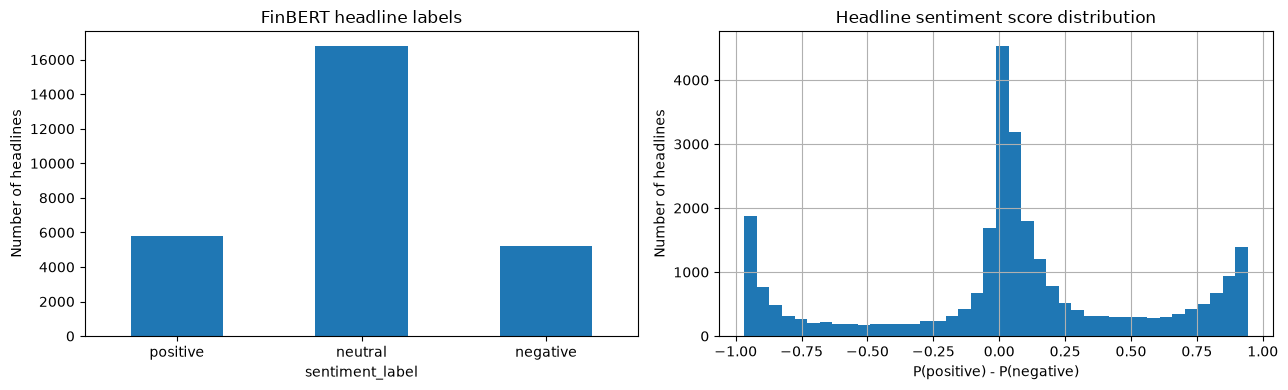

In [7]:
if scored_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    scored_news["sentiment_label"].value_counts().reindex(
        ["positive", "neutral", "negative"]
    ).plot(kind="bar", ax=axes[0])
    axes[0].set_title("FinBERT headline labels")
    axes[0].set_ylabel("Number of headlines")
    axes[0].tick_params(axis="x", rotation=0)

    scored_news["sentiment_score"].hist(bins=40, ax=axes[1])
    axes[1].set_title("Headline sentiment score distribution")
    axes[1].set_xlabel("P(positive) - P(negative)")
    axes[1].set_ylabel("Number of headlines")
    plt.tight_layout()
    plt.show()

## 9. How the historical training dataset is constructed

The project intentionally separates the complete archive from the historical training sample.

### 9.1 Full scored archive

`news_sentiment_scored.csv` is retained in full. It is not truncated by the monthly cap.

### 9.2 Historical sampling

`src/build_training_dataset.py` creates a separate training article set:

- Each **completed calendar month** is capped at 500 articles.
- Months with 500 or fewer articles are retained in full.
- Months above 500 are sampled across represented feature dates using a daily-stratified allocation.
- Sampling within a day is random without replacement, with a deterministic seed derived from the date.
- The **current calendar month remains uncapped**.
- The sampling audit records before/after article counts, represented days, and min/max selected articles per day.

The 500 cap is a project design choice to constrain the influence of high-volume months. It is not a statistical law and does not guarantee that the selected articles are representative in topic, source, or event importance.

### 9.3 Aggregation and merge

The sampled article set is aggregated by feature date into:

- article count
- unique source count
- mean and median sentiment
- positive, negative, and neutral fractions

These daily news aggregates are merged one-to-one with the daily market dataset. The code raises an error if required sampled aggregates are missing for any market session rather than silently filling those rows.

Seven-calendar-day rolling features are then generated from the sampled scored articles and joined to create `model_dataset.csv`.

### 9.4 Training/live data distinction

Historical walk-forward training uses the sampled archive. The live seven-day news features are rebuilt from the **full uncapped scored archive**. This was an explicit project design.

The count-valued features are transformed with:

\[
x' = \log(1+x)
\]

This is applied to `article_count`, `unique_sources`, `news_7d_article_count`, and `news_7d_unique_sources` in both historical and live inputs. It compresses large counts but does not make the sampled and full archives identical. Sentiment values and fractions are not log-transformed.

In [8]:
training_path = PROCESSED_DIR / "model_dataset.csv"
sampled_articles_path = PROCESSED_DIR / "news_sentiment_training.csv"
sampled_daily_path = PROCESSED_DIR / "news_sentiment_daily_training.csv"
audit_path = PROCESSED_DIR / "sampling_audit.csv"

if audit_path.exists():
    sampling_audit = pd.read_csv(audit_path)
    print("Sampling audit:")
    display(sampling_audit.tail(15))
    print("Total articles before sampling:", sampling_audit["articles_before"].sum())
    print("Total articles after sampling:", sampling_audit["articles_after"].sum())

if sampled_articles_path.exists():
    sampled_articles = pd.read_csv(sampled_articles_path)
    print("\nSampled article archive:", sampled_articles.shape)
    display(sampled_articles.head())

if training_path.exists():
    model_data = pd.read_csv(training_path, parse_dates=["date"])
    print("\nModel dataset:", model_data.shape)
    print("Date range:", model_data["date"].min(), "to", model_data["date"].max())
    display(model_data.head())
    display(model_data.dtypes.to_frame("dtype"))

Sampling audit:


,month,articles_before,articles_after,cap,status,represented_days,min_per_day,max_per_day
55,2025-08,473,473,500,completed_month_under_cap,19,14,48
56,2025-09,432,432,500,completed_month_under_cap,22,7,36
57,2025-10,578,500,500,closed_month_uniform_daily_stratified,21,13,29
58,2025-11,314,314,500,completed_month_under_cap,19,4,31
59,2025-12,456,456,500,completed_month_under_cap,22,5,47
60,2026-01,368,368,500,completed_month_under_cap,20,3,48
61,2026-02,279,279,500,completed_month_under_cap,20,5,41
62,2026-03,382,382,500,completed_month_under_cap,19,13,33
63,2026-04,693,500,500,closed_month_uniform_daily_stratified,20,7,29
64,2026-05,474,474,500,completed_month_under_cap,19,8,74


Total articles before sampling: 27855
Total articles after sampling: 27353

Sampled article archive: (27353, 13)


,id,title,published_at,source,url,published_at_ist,feature_date,sentiment_positive,sentiment_negative,sentiment_neutral,sentiment_score,sentiment_label,_source_key
0,19914,"Antony Waste stock makes robust debut, lists a...",2021-01-01 08:00:00+00:00,Livemint,https://news.google.com/rss/articles/CBMi1AFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.920009,0.010476,0.069515,0.909534,positive,livemint
1,11047,Car review: BMW's new 420i is eye candy with n...,2021-01-01 08:00:00+00:00,The Straits Times,https://news.google.com/rss/articles/CBMiogFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.229283,0.012575,0.758142,0.216707,neutral,the straits times
2,33645,Should India Abandon Inflation Targeting? Nirm...,2021-01-01 08:00:00+00:00,NDTV Profit,https://news.google.com/rss/articles/CBMinAFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.054020,0.054104,0.891876,-0.000085,neutral,ndtv profit
3,21407,TCS completes acquisition of Postbank Systems ...,2021-01-01 08:00:00+00:00,The Economic Times,https://news.google.com/rss/articles/CBMi2gFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.285592,0.012340,0.702068,0.273252,neutral,the economic times
4,16728,"The biggest market winners and losers of 2020,...",2021-01-01 08:00:00+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMixwFBV...,2021-01-01 13:30:00+05:30,2021-01-01,0.034478,0.063159,0.902363,-0.028681,neutral,moneycontrol.com



Model dataset: (1439, 25)
Date range: 2021-01-01 00:00:00 to 2026-10-29 00:00:00


,date,open,high,low,close,volume,adj_close,daily_return,daily_return_pct,target_next_session_return_pct,...,positive_fraction,negative_fraction,neutral_fraction,news_7d_article_count,news_7d_unique_sources,news_7d_mean_sentiment,news_7d_median_sentiment,news_7d_positive_fraction,news_7d_negative_fraction,news_7d_neutral_fraction
0,2021-01-01,13996.099609,14049.849609,13991.349609,14018.500000,358100.0,14018.500000,NaN,NaN,0.816067,...,0.166667,0.000000,0.833333,6,6,0.231023,0.116058,0.166667,0.000000,0.833333
1,2021-01-04,14104.349609,14147.950195,13953.750000,14132.900391,495000.0,14132.900391,0.008161,0.816067,0.471238,...,0.272727,0.181818,0.545455,17,14,0.136475,0.026357,0.235294,0.117647,0.647059
2,2021-01-05,14075.150391,14215.599609,14048.150391,14199.500000,492500.0,14199.500000,0.004712,0.471238,-0.375013,...,0.250000,0.083333,0.666667,29,17,0.168884,0.043007,0.241379,0.103448,0.655172
3,2021-01-06,14240.950195,14244.150391,14039.900391,14146.250000,632300.0,14146.250000,-0.003750,-0.375013,-0.062917,...,0.400000,0.200000,0.400000,34,19,0.161271,0.050622,0.264706,0.117647,0.617647
4,2021-01-07,14253.750000,14256.250000,14123.099609,14137.349609,559200.0,14137.349609,-0.000629,-0.062917,1.484722,...,0.000000,0.333333,0.666667,40,21,0.092489,0.045868,0.225000,0.150000,0.625000


,dtype
date,datetime64[us]
open,float64
high,float64
low,float64
close,float64
volume,float64
adj_close,float64
daily_return,float64
daily_return_pct,float64
target_next_session_return_pct,float64


## 10. Feature engineering and final model matrix

The current model dataset contains market variables, daily sentiment aggregates, and seven-day rolling news/sentiment variables. `generate_forecast.py` and `adaptive_model_selection.py` add lagged/rolling market features.

### Market and lag features

| Feature | Construction / interpretation |
|---|---|
| `daily_return_pct` | Current session's close-to-close percentage return |
| `return_lag1` | Previous session return |
| `return_lag2` | Return two sessions earlier |
| `return_lag5` | Return five sessions earlier |
| `return_lag10` | Return ten sessions earlier (used by volatility model) |
| `volatility_5` | Rolling standard deviation of daily returns over five sessions |
| `volatility_20` | Rolling standard deviation over 20 sessions (used by volatility model) |
| `momentum_5` | Sum of returns over five sessions (volatility model) |
| `momentum_10` | Sum of returns over ten sessions (volatility model) |
| `sentiment_lag1` | Previous session's daily mean sentiment |

### Daily sentiment features

- `mean_sentiment`, `median_sentiment`
- `positive_fraction`, `negative_fraction`, `neutral_fraction`

### Seven-calendar-day features

For each market session, `news_features.py` takes the inclusive interval from `session_date - 6 days` through `session_date`, then computes:

- `news_7d_article_count`
- `news_7d_unique_sources`
- `news_7d_mean_sentiment`
- `news_7d_median_sentiment`
- `news_7d_positive_fraction`
- `news_7d_negative_fraction`
- `news_7d_neutral_fraction`

These are calendar-day windows, not seven trading sessions. They include the forecast-origin date and preceding six calendar days.

### Count transformation

The four count columns are compressed with `numpy.log1p`. For example:

\[
\log(1+10) \approx 2.40,\qquad \log(1+100) \approx 4.62
\]

A tenfold increase in raw count therefore produces a smaller increase on the transformed scale. The transform is not a cap: very large values remain larger than smaller values.

### Missing-value treatment and scaling

The model pipelines use:

1. `SimpleImputer(strategy="median")`
2. `StandardScaler()`
3. estimator (Ridge or Logistic Regression)

The imputer and scaler are fitted within each training pipeline, not globally on the full dataset. This is important to avoid using future test-set distribution information during walk-forward evaluation.

The StandardScaler standardizes predictors approximately as:

\[
z = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
\]

where \(\mu_{\text{train}}\) and \(\sigma_{\text{train}}\) are estimated from the training subset. It is not a replacement for the `log1p` transformation; they serve different purposes.

,count,mean,std,min,25%,50%,75%,max
open,1439.0,20627.913551,3626.922163,13758.599609,17451.125000,20155.949219,24176.200195,2.633370e+04
high,1439.0,20719.515068,3636.566295,13898.250000,17568.325195,20195.349609,24272.900391,2.637320e+04
low,1439.0,20513.203887,3622.651507,13596.750000,17360.775391,20115.699219,24055.225586,2.621005e+04
close,1439.0,20619.137397,3627.590568,13634.599609,17494.474609,20133.300781,24151.549805,2.632855e+04
volume,1439.0,326396.525365,130394.438739,0.000000,245050.000000,292400.000000,375950.000000,1.198000e+06
adj_close,1439.0,20619.137397,3627.590568,13634.599609,17494.474609,20133.300781,24151.549805,2.632855e+04
daily_return,1438.0,0.000379,0.008885,-0.059294,-0.004249,0.000420,0.005508,4.742351e-02
daily_return_pct,1438.0,0.037909,0.888508,-5.929360,-0.424932,0.042023,0.550848,4.742351e+00
target_next_session_return_pct,1438.0,0.037909,0.888508,-5.929360,-0.424932,0.042023,0.550848,4.742351e+00
article_count,1439.0,19.008339,18.677519,2.000000,11.000000,16.000000,23.000000,3.600000e+02


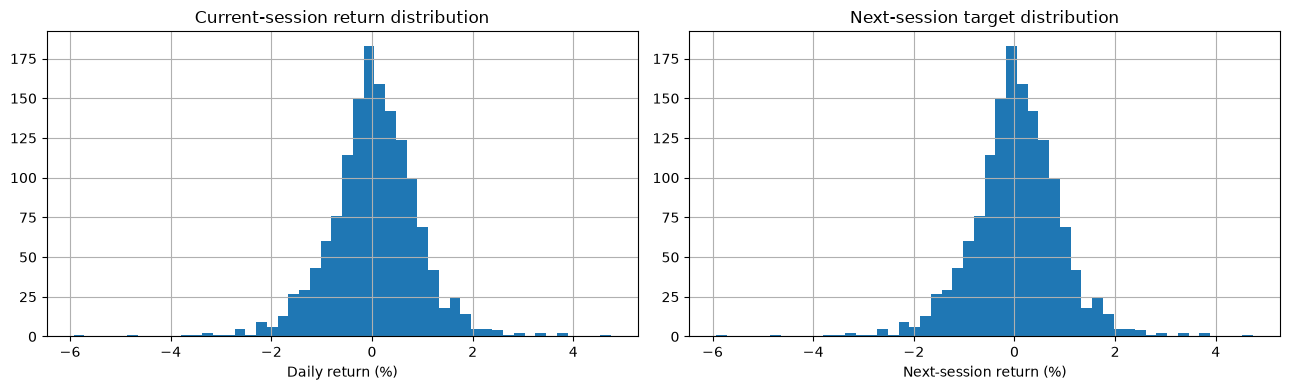

In [9]:
if training_path.exists():
    model_data = pd.read_csv(training_path, parse_dates=["date"])
    numeric_summary = model_data.select_dtypes(include="number").describe().T
    display(numeric_summary)

    target_col = "target_next_session_return_pct"
    if target_col in model_data:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        model_data["daily_return_pct"].dropna().hist(bins=50, ax=axes[0])
        axes[0].set_title("Current-session return distribution")
        axes[0].set_xlabel("Daily return (%)")

        model_data[target_col].dropna().hist(bins=50, ax=axes[1])
        axes[1].set_title("Next-session target distribution")
        axes[1].set_xlabel("Next-session return (%)")
        plt.tight_layout()
        plt.show()

## 11. Forecast algorithms

The current forecasting code uses three model tasks and a separate adaptive selector.

### 11.1 Return regression: Ridge Regression

The return models are Ridge regressions with `alpha=10.0`, wrapped in a preprocessing pipeline:

`median imputation → StandardScaler → Ridge`

Ridge minimizes squared prediction error with an L2 penalty:

\[
\hat{\beta} =
\arg\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-X_i\beta)^2
+\alpha\sum_{j=1}^{p}\beta_j^2
\right]
\]

The penalty discourages very large coefficients and can reduce variance when predictors are correlated. It does not guarantee that the features contain predictive information.

Two model families are fitted:

- **Market model:** market returns, lagged returns, volatility, daily counts, and seven-day news volume/source features.
- **Market + sentiment model:** market features plus daily and seven-day sentiment variables.

### 11.2 Direction classification: Logistic Regression

The direction label is 1 if the next-session return is positive, otherwise 0. The classifier uses the same median-imputation and standardization steps, followed by Logistic Regression (`max_iter=1000`, `random_state=42`).

Logistic regression models:

\[
P(Y=1\mid X)=\frac{1}{1+\exp[-(\beta_0+X\beta)]}
\]

The output is interpreted as estimated probability of an UP session. It is not automatically a calibrated probability. Calibration must be checked against a sufficiently large set of genuinely prospective predictions.

### 11.3 Volatility classification

The volatility target is defined using a rolling historical threshold:

- Lookback: 252 sessions.
- Minimum history: 60 sessions.
- Threshold: 80th percentile of absolute daily returns known through the feature date.
- Label: 1 when the *next-session absolute return* exceeds that threshold.

Formally:

\[
q_t = Q_{0.80}\left(|r_{t-251}|,\ldots,|r_t|\right)
\]

subject to the minimum-history requirement, and:

\[
v_t = \mathbb{1}(|y_t| > q_t)
\]

A Logistic Regression classifier estimates the probability of this event. The 20% and 30% alert indicators are operational thresholds applied to that estimated probability; they are not the volatility target definition.

### 11.4 Adaptive model selection

`adaptive_model_selection.py` compares:

- Expanding training window: all eligible historical observations before each test point.
- Rolling training window: up to the previous 252 trading sessions.
- Baseline: historical mean return.
- Market model.
- Sentiment model.

It evaluates recent out-of-sample predictions over the most recent two calendar months. At least 30 recent predictions are required.

For return selection:
- Metric: MAE.
- A feature model must improve MAE by at least 2% relative to the expanding mean-return baseline.
- Otherwise the expanding mean-return baseline is selected.

For direction selection:
- Metric: Brier score (lower is better).
- Direction accuracy is used as a tie-breaker.

The selector is a heuristic based on a short recent period. A selection from 41 predictions is noisy and can change with a small number of outcomes.

## 12. Walk-forward evaluation: why not a random train/test split?

This is time-series forecasting. A random split would mix past and future observations, allowing training to use information from dates later than some test dates. That is not a realistic simulation of forecasting.

The walk-forward process is chronological:

1. Choose a test session \(t\).
2. Train only on rows with targets already known before \(t\).
3. Predict the next-session outcome for \(t\).
4. Move forward to the next test session.
5. Repeat.

The expanding window keeps all prior eligible training rows. The rolling window retains only the latest 252 eligible sessions.

### Metrics

**MAE (return regression):**

\[
MAE = \frac{1}{n}\sum_i |y_i-\hat y_i|
\]

Lower is better; it measures average absolute return-prediction error in percentage points.

**RMSE:**

\[
RMSE = \sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}
\]

It penalizes large errors more heavily than MAE.

**Directional accuracy:** fraction of non-flat observations where the predicted direction is correct.

**Brier score:**

\[
BS = \frac{1}{n}\sum_i(p_i-o_i)^2
\]

where \(p_i\) is predicted probability of UP and \(o_i\) is 1 for an actual UP session and 0 otherwise. Lower is better. Brier score evaluates both probability accuracy and discrimination; it does not alone prove calibration.

The project’s adaptive-selection file stores the recent walk-forward metrics and selected configurations.

In [10]:
selection_csv = PROCESSED_DIR / "adaptive_model_selection.csv"
selection_json = PROCESSED_DIR / "adaptive_model_selection.json"

if selection_csv.exists():
    selection_metrics = pd.read_csv(selection_csv)
    display(selection_metrics)
if selection_json.exists():
    selection_config = json.loads(selection_json.read_text(encoding="utf-8"))
    print(json.dumps(selection_config, indent=2))

,window_mode,model_family,n_predictions,mae_pct,rmse_pct,direction_accuracy,direction_brier,period_start,period_end
0,expanding,baseline,41,0.656461,0.803322,0.390244,0.257617,2026-08-28,2026-10-28
1,expanding,market,41,0.675076,0.810898,0.341463,0.260946,2026-08-28,2026-10-28
2,expanding,sentiment,41,0.678315,0.816637,0.414634,0.263657,2026-08-28,2026-10-28


{
  "selection_date": "2026-10-28",
  "evaluation_start_date": "2026-08-28",
  "evaluation_end_date": "2026-10-28",
  "recent_prediction_count": 41,
  "minimum_predictions": 30,
  "rolling_window_sessions": 252,
  "return_selection": {
    "family": "baseline",
    "window_mode": "expanding"
  },
  "direction_selection": {
    "family": "market",
    "window_mode": "expanding"
  },
  "fallback_reason": "No feature model beat the expanding mean-return baseline by the required 2% MAE margin; baseline selected.",
  "selection_method": "recent_two_calendar_months_walk_forward_v1"
}


## 13. How the live forecast is assembled

At forecast time, `generate_forecast.py`:

1. Loads `model_dataset.csv` (the sampled historical training data).
2. Adds lagged market, volatility, momentum, and volatility-target features.
3. Applies `log1p` to the four count predictors.
4. Takes the latest market-session row.
5. Loads the full scored article archive.
6. Rebuilds the latest trailing seven-calendar-day features from that full archive.
7. Replaces the latest session's daily news/sentiment aggregates with full-archive aggregates.
8. Applies `log1p` to the live count predictors using the same transformation.
9. Runs adaptive selection on historical walk-forward results.
10. Fits the selected configuration and also fits the market-only, market-plus-sentiment, and volatility models.
11. Writes `latest_forecast.csv` and stores the forecast in SQLite forecast history.

### What the forecast fields mean

| Output | Meaning |
|---|---|
| `market_predicted_return_pct` | Ridge market-only predicted next-session return |
| `market_probability_up` | Logistic market-only estimated probability of positive next-session return |
| `sentiment_predicted_return_pct` | Ridge market + sentiment predicted return |
| `sentiment_probability_up` | Logistic market + sentiment estimated probability of UP |
| `selected_predicted_return_pct` | Return forecast from the adaptively selected model |
| `selected_direction_probability_up` | UP probability from the adaptively selected direction model |
| `volatility_probability` | Estimated probability that absolute next-session return exceeds the rolling threshold |
| `volatility_threshold_pct` | Current rolling 80th-percentile absolute-return threshold |
| `volatility_alert_20` / `_30` | Whether volatility probability crosses 20% / 30% |

The individual model outputs and adaptive-selected outputs are not interchangeable. In the latest successful run, the market-only Ridge forecast was +0.6751%, while the selected return strategy was the expanding mean-return baseline at +0.0379%. The selected direction model was the market classifier with estimated P(UP) of 76.8%.

In [11]:
forecast_path = PROCESSED_DIR / "latest_forecast.csv"
if forecast_path.exists():
    latest_forecast = pd.read_csv(forecast_path)
    print("Forecast file shape:", latest_forecast.shape)
    display(latest_forecast.T)
else:
    print("Forecast file not found:", forecast_path)

Forecast file shape: (1, 33)


,0
dataset,Monthly-sampled historical training; full-arch...
dataset_file,model_dataset.csv
live_news_source,news_sentiment_scored.csv (uncapped full archive)
historical_news_source,news_sentiment_training.csv (500 per completed...
forecast_origin_date,2026-10-29
target_session_date,NaN
created_at_utc,2026-10-30T12:57:57.476975+00:00
training_rows,1438
market_predicted_return_pct,0.675105
market_direction,UP


## 14. Latest successful run: observed project snapshot

The successful run log supplied for this project reported:

| Quantity | Observed value |
|---|---:|
| Aligned/scored articles | 27,855 |
| Sampled training articles | 27,353 |
| Trading sessions | 1,439 |
| Historical rows with known next-session target | 1,438 |
| Recent walk-forward predictions | 41 |
| Walk-forward evaluation period | 28 Aug 2026 – 28 Oct 2026 |
| Latest market session in that run | 29 Oct 2026 |

Forecast snapshot from that run:

| Forecast | Value |
|---|---:|
| Market-only return | +0.6751% |
| Market-only P(UP) | 76.8% |
| Market + sentiment return | +0.6336% |
| Market + sentiment P(UP) | 75.1% |
| Volatility probability | 25.9% |
| Volatility threshold | 0.9777% |
| Adaptive-selected return | +0.0379% (baseline / expanding) |
| Adaptive-selected direction | Market / expanding, P(UP)=76.8% |

These are historical log values, not a claim about current market conditions. Your local `latest_forecast.csv` is the source of truth for the latest run on your machine.

### Critical interpretation

The model outputs are research estimates. In the supplied run:

- No feature model beat the expanding mean-return baseline by the required 2% MAE margin.
- Direction probabilities had not been demonstrated to be calibrated.
- There were zero evaluated forecasts from the current model version.
- Seven forecasts were pending outcome evaluation.
- The market-price data ended on 29 October 2026 because the previous Yahoo refresh timed out.

Consequently, the +76.8% estimated UP probability should not be described as a 76.8% real-world chance unless prospective calibration supports that interpretation. And the pipeline’s successful execution is not evidence of predictive skill.

## 15. Forecast outcome tracking and prospective validation

`record_forecast_outcome.py` checks forecast records stored in SQLite against later available market-price sessions.

For each forecast it tries to resolve the target session date. When the target price is available, it records:

- actual next-session return
- actual direction (UP / DOWN / FLAT)
- absolute actual return
- whether the absolute return exceeded the saved volatility threshold
- evaluation timestamp

The official scorecard filters to the current model version so that results from older model versions are not mixed into the current model's evaluation.

This is important because a forecast cannot be evaluated at the moment it is generated. It becomes evaluable only after the corresponding next-session market close is present in the local price history.

**Prospective evaluation is the decisive test.** Keep forecasts immutable, collect actual outcomes over time, and report MAE/RMSE, directional accuracy, Brier score, and volatility classification metrics over a meaningful sample. Do not repeatedly alter the model and then combine forecasts from different versions into one scorecard.

In [12]:
outcome_path = PROCESSED_DIR / "forecast_outcome_history.csv"
if outcome_path.exists():
    outcomes = pd.read_csv(outcome_path)
    print("Official outcome history shape:", outcomes.shape)
    display(outcomes.tail(10))
else:
    print("Outcome file not found:", outcome_path)

if DB_PATH.exists():
    with sqlite3.connect(DB_PATH) as con:
        names = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type='table'", con
        )["name"].tolist()
    if "forecast_history" in names:
        with sqlite3.connect(DB_PATH) as con:
            forecast_db = pd.read_sql_query(
                "SELECT * FROM forecast_history ORDER BY id DESC LIMIT 10", con
            )
        print("\nMost recent forecast-history records:")
        display(forecast_db)

Official outcome history shape: (0, 26)


,forecast_origin_date,target_session_date,market_predicted_return_pct,market_direction,market_probability_up,sentiment_predicted_return_pct,sentiment_direction,sentiment_probability_up,volatility_probability,volatility_threshold_pct,...,selected_model_name,selected_window_mode,selected_predicted_return_pct,selected_direction_model_name,selected_direction_window_mode,selected_direction_probability_up,adaptive_selection_date,adaptive_recent_prediction_count,adaptive_selection_method,model_version



Most recent forecast-history records:


,id,forecast_origin_date,target_session_date,created_at_utc,training_rows,market_predicted_return_pct,market_direction,market_probability_up,sentiment_predicted_return_pct,sentiment_direction,...,actual_volatile,selected_model_name,selected_window_mode,selected_predicted_return_pct,selected_direction_model_name,selected_direction_window_mode,selected_direction_probability_up,adaptive_selection_date,adaptive_recent_prediction_count,adaptive_selection_method
0,17,2026-10-29,NaN,2026-10-30T12:57:57.476975+00:00,1438,0.675105,UP,0.767979,0.633591,UP,...,NaN,baseline,expanding,0.037909,market,expanding,0.767979,2026-10-28,41.0,recent_two_calendar_months_walk_forward_v1
1,16,2026-10-29,NaN,2026-10-30T12:43:07.008155+00:00,1438,0.675105,UP,0.767979,0.633591,UP,...,NaN,baseline,expanding,0.037909,market,expanding,0.767979,2026-10-28,41.0,recent_two_calendar_months_walk_forward_v1
2,14,2026-10-29,NaN,2026-10-30T12:12:58.906476+00:00,1438,0.273592,UP,0.359774,0.280200,UP,...,NaN,baseline,expanding,0.037909,market,expanding,0.359774,2026-10-28,41.0,recent_two_calendar_months_walk_forward_v1
3,13,2026-10-29,NaN,2026-10-30T11:50:04.454476+00:00,1438,0.254429,UP,0.349031,0.259333,UP,...,NaN,baseline,expanding,0.037909,market,expanding,0.349031,2026-10-28,41.0,recent_two_calendar_months_walk_forward_v1
4,12,2026-10-29,NaN,2026-10-29T19:12:59.945794+00:00,1438,0.171520,UP,0.542801,0.238703,UP,...,NaN,baseline,expanding,0.037909,sentiment,expanding,0.586449,2026-10-28,41.0,recent_two_calendar_months_walk_forward_v1
5,11,2026-10-29,NaN,2026-10-29T18:45:41.872758+00:00,1438,0.146410,UP,0.522511,0.192526,UP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,10,2026-10-29,NaN,2026-10-29T18:39:28.640603+00:00,1438,0.409071,UP,0.503568,0.409965,UP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,6,2026-10-28,2026-10-29,2026-10-29T06:03:07.283158+00:00,1437,0.261139,UP,0.546513,0.254173,UP,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,5,2026-10-27,2026-10-28,2026-10-29T05:37:05.993651+00:00,1436,0.166307,UP,0.542056,0.168806,UP,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1,2026-10-27,2026-10-28,2026-10-28T12:41:48.636168+00:00,1436,0.275268,UP,0.427631,0.265867,UP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 16. Limitations, risks, and what should improve next

These are the main methodological constraints visible in the implemented pipeline.

### 16.1 News coverage and sampling bias
Google News RSS search terms do not guarantee comprehensive coverage. The 500-article monthly cap also changes the historical article distribution, while the current month is uncapped. Daily stratification preserves date coverage better than simple random month-wide sampling, but it does not ensure representativeness by source, topic, market relevance, or event severity.

### 16.2 Historical/live distribution difference
Historical news features are based on the sampled archive; live seven-day features are based on the full archive. `log1p` compresses counts but does not remove this distribution difference. It also does not correct changes in publisher mix or sentiment composition.

### 16.3 Headline-only sentiment
FinBERT sees the headline, not the full article. It cannot reliably infer the magnitude, novelty, causal direction, or index-wide relevance of every event.

### 16.4 Timestamp and leakage risk
The 15:45 IST cutoff is intended to enforce information availability, but its validity depends on reliable publication timestamps and forecast execution after the cutoff. This should be audited with real examples.

### 16.5 Short adaptive-selection window
The selector uses recent two-calendar-month performance and requires 30 observations. Forty-one predictions are still a small sample; a few unusual sessions can materially change MAE or Brier rankings.

### 16.6 Calibration and statistical significance
Logistic Regression outputs probabilities, but the outputs are not automatically calibrated. Calibration curves, reliability diagrams, Brier scores, and sufficient prospective observations are needed. A model can have acceptable directional accuracy while producing poor probabilities.

### 16.7 No trading-system validation
The project does not establish profitability. It does not fully model transaction costs, slippage, execution constraints, position sizing, drawdowns, or risk-adjusted returns. Do not interpret a directional forecast as a trading instruction.

## 17. Reproducibility checklist

Before presenting or evaluating a forecast, record:

- model version
- forecast origin date and actual target session date
- last market-price date
- news archive coverage and collection timestamp
- whether the run refreshed collection or used `--skip-refresh`
- training dataset row count and date range
- sampled article count and sampling audit
- adaptive return and direction selections
- model outputs and warnings
- subsequent actual return and evaluation status

The pipeline's important artifacts are:

| File | Role |
|---|---|
| `data/raw/recent_news_2026.csv` | Incrementally collected recent RSS articles |
| `data/raw/historical_news_merged_2021_2025.csv` | Historical news input, when present |
| `data/raw/nifty50_prices.csv` | Raw NIFTY 50 history |
| `data/processed/nifty50_processed.csv` | Cleaned price data and derived returns |
| `data/market.db` | Persistent news, price, and forecast history |
| `data/processed/news_market_alignment.csv` | Article-level market-session mapping |
| `data/processed/news_market_daily.csv` | Daily market + article-count dataset |
| `data/processed/news_sentiment_scored.csv` | Full scored headline archive |
| `data/processed/news_sentiment_daily.csv` | Full-archive daily sentiment aggregates |
| `data/processed/news_sentiment_training.csv` | Sampled historical article set |
| `data/processed/sampling_audit.csv` | Monthly sampling audit |
| `data/processed/model_dataset.csv` | Final historical model matrix |
| `data/processed/adaptive_model_selection.csv/.json` | Walk-forward model-selection results |
| `data/processed/latest_forecast.csv` | Latest forecast output |
| `data/processed/forecast_outcome_history.csv` | Prospective outcome history |

---

## 18. Final summary

The project is a chronological, news-informed NIFTY 50 forecasting research pipeline:

1. Collect headlines and daily index prices.
2. Store raw observations in SQLite and CSV artifacts.
3. clean and deduplicate records.
4. Assign news to trading sessions using a 15:45 IST cutoff.
5. Score each headline with FinBERT.
6. Aggregate sentiment and news-volume features.
7. Sample completed historical months for training while retaining the full scored archive.
8. Build market, lagged, rolling, and seven-day news features.
9. Apply `log1p` to count features, then median imputation and standardization inside model pipelines.
10. Compare expanding/rolling Ridge and Logistic Regression models using walk-forward predictions.
11. Generate return, direction, and volatility forecasts.
12. Record actual outcomes when future market prices become available.

**The pipeline is operational. Predictive validity remains an empirical question that must be answered through prospective evaluation.**